# EDA Summary
**The 4 main findings**
1. A tweet is labelled misleading in two steps (a writer flags it, then different raters agree). Most flagged tweets are missing context
2. A note is shown by agreement between rater groups, not by majority vote.
3. Raters mostly disagree about the tweet itself ("note not needed"), which may be a signal of contested or political content.
4. 63% of the Helpful notes are written by AI accounts.

In [31]:
import glob

import matplotlib.pyplot as plt
import pandas as pd

# ids are 19 digits, read them as strings so pandas doesn't round them
ids = {"noteId": str, "tweetId": str, "noteAuthorParticipantId": str, "raterParticipantId": str, "participantId": str}

folder = "dataset/10-05_10-13/"
tweets = pd.read_csv(folder + "tweets.csv", dtype=ids)
notes = pd.read_csv(folder + "notes.csv", dtype=ids)
status = pd.read_csv(folder + "note_status.csv", dtype=ids)
ratings = pd.read_csv(folder + "ratings.csv", dtype=ids)

saudi_folder = "dataset/tweet_2109031558967615703/"
saudi_notes = pd.read_csv(saudi_folder + "notes.csv", dtype=ids)
saudi_status = pd.read_csv(saudi_folder + "note_status.csv", dtype=ids)
saudi_ratings = pd.read_csv(saudi_folder + "ratings.csv", dtype=ids)

# user file from the raw data (status + rater group for each user)
users = pd.read_csv(
    "data/userEnrollment-00000.tsv",
    sep="\t",
    usecols=["participantId", "enrollmentState", "modelingPopulation", "modelingGroup"],
    dtype={"participantId": str},
)
users = users.set_index("participantId")

print("tweets:", len(tweets), "| notes:", len(notes), "| ratings:", len(ratings), "| raters:", ratings["raterParticipantId"].nunique())

tweets: 500 | notes: 500 | ratings: 43656 | raters: 30747


## 1. How a tweet gets labelled misleading

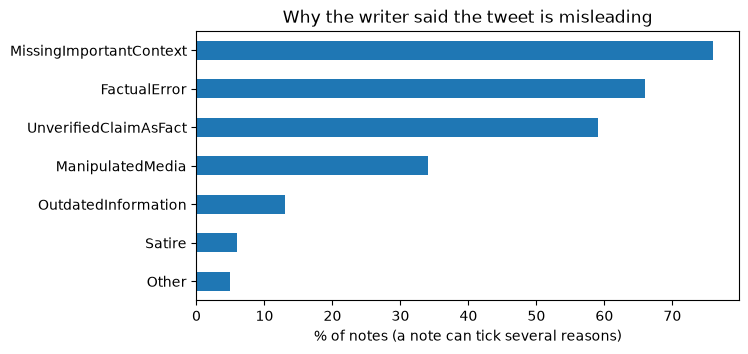

In [32]:
# % of notes that ticked each reason
reason_columns = [c for c in notes.columns if c.startswith("misleading")]
reasons = (notes[reason_columns].mean() * 100).round(0).sort_values()
reasons.index = [c.replace("misleading", "") for c in reasons.index]

reasons.plot(kind="barh", color="tab:blue", figsize=(7, 3.5), title="Why the writer said the tweet is misleading")
plt.xlabel("% of notes (a note can tick several reasons)")
plt.show()

In [30]:
example = notes[["summary", "classification", "misleadingMissingImportantContext", "misleadingFactualError",
                 "misleadingManipulatedMedia", "misleadingUnverifiedClaimAsFact"]].sample(10, random_state=1)
example["summary"] = example["summary"].str[:60]
example

,summary,classification,misleadingMissingImportantContext,misleadingFactualError,misleadingManipulatedMedia,misleadingUnverifiedClaimAsFact
304,Katie's question implies the exploit was unspe...,MISINFORMED_OR_POTENTIALLY_MISLEADING,1,0,0,1
340,Federal law requires licensed firearms dealers...,MISINFORMED_OR_POTENTIALLY_MISLEADING,1,1,1,1
47,Patriots 29 Bills 26 https://www.espn.com...,MISINFORMED_OR_POTENTIALLY_MISLEADING,1,1,0,0
67,Ukraine's Air Force says radar detected the ta...,MISINFORMED_OR_POTENTIALLY_MISLEADING,0,0,0,1
479,The Eagles did not win this game. Philadelphia...,MISINFORMED_OR_POTENTIALLY_MISLEADING,0,1,0,0
485,The claim of an &quot;unprovoked&quot; attack ...,MISINFORMED_OR_POTENTIALLY_MISLEADING,0,0,0,0
310,The video is a digitally manipulated version o...,MISINFORMED_OR_POTENTIALLY_MISLEADING,1,1,1,1
31,It has already been coined https://x.com/secl...,MISINFORMED_OR_POTENTIALLY_MISLEADING,0,1,0,1
249,"The screenshot is a fabricated image, not a re...",MISINFORMED_OR_POTENTIALLY_MISLEADING,1,1,1,1
90,Post implies Mike Hayden is the current govern...,MISINFORMED_OR_POTENTIALLY_MISLEADING,1,0,0,0


## 2. A note is shown by agreement, not by majority

In [33]:
# % Helpful ratings for every note
helpful_share = (ratings["helpfulnessLevel"] == "HELPFUL").groupby(ratings["noteId"]).mean() * 100

print(f"lowest % Helpful of a shown note: {helpful_share.min():.0f}%")
print("shown notes with less than 70% Helpful ratings:", (helpful_share < 70).sum())

lowest % Helpful of a shown note: 56%
shown notes with less than 70% Helpful ratings: 21


In [34]:
# the 4 notes on the Saudi tweet, oldest first
saudi_notes = saudi_notes.sort_values("createdAtMillis")
rows = []
for i, note_id in enumerate(saudi_notes["noteId"]):
    levels = saudi_ratings.loc[saudi_ratings["noteId"] == note_id, "helpfulnessLevel"]
    shown = saudi_status.set_index("noteId").loc[note_id, "currentStatus"] == "CURRENTLY_RATED_HELPFUL"
    rows.append({"note": f"Note {i + 1}", "ratings": len(levels), "% Helpful": round((levels == "HELPFUL").mean() * 100), "shown on X": shown})

pd.DataFrame(rows)

,note,ratings,% Helpful,shown on X
0,Note 1,113,77,False
1,Note 2,101,76,False
2,Note 3,77,83,False
3,Note 4,165,82,True


Groups = groups of raters that X makes based on region, country or language (X's guide, "Note ranking"). The numbers (24, 13) are just IDs, X doesn't say which region each one is.

In [35]:
# how the 2 biggest rater groups rated the Saudi notes
saudi_ratings["group"] = saudi_ratings["raterParticipantId"].map(users["modelingGroup"])
for group in [24, 13]:
    levels = saudi_ratings.loc[saudi_ratings["group"] == group, "helpfulnessLevel"]
    print(f"group {group}: {len(levels)} ratings, {(levels == 'HELPFUL').mean() * 100:.0f}% Helpful")

group 24: 330 ratings, 94% Helpful
group 13: 63 ratings, 43% Helpful


In [37]:
example = pd.concat([
    saudi_ratings[saudi_ratings["group"] == 24].sample(5, random_state=1),
    saudi_ratings[saudi_ratings["group"] == 13].sample(5, random_state=1),
])
example = example[["noteId", "raterParticipantId", "group", "helpfulnessLevel"]]
example["raterParticipantId"] = example["raterParticipantId"].str[:10]
example

,noteId,raterParticipantId,group,helpfulnessLevel
81,2109035483950932219,37430481F9,24.0,HELPFUL
377,2109061654621098457,1EB775CB69,24.0,HELPFUL
248,2109061291952275812,37430481F9,24.0,HELPFUL
265,2109061291952275812,092455A270,24.0,HELPFUL
394,2109061654621098457,1345B5656A,24.0,HELPFUL
168,2109043751892942901,6D12C69A6D,13.0,HELPFUL
285,2109061291952275812,1DBA05CF94,13.0,NOT_HELPFUL
356,2109061654621098457,012BC9E50A,13.0,NOT_HELPFUL
185,2109043751892942901,B23E05EC2B,13.0,SOMEWHAT_HELPFUL
444,2109061654621098457,2E3671D074,13.0,HELPFUL


## 3. Where do raters disagree?

In [38]:
# top 5 reasons people gave for Not Helpful
not_helpful = ratings[ratings["helpfulnessLevel"] == "NOT_HELPFUL"]
reason_columns = [c for c in ratings.columns if c.startswith("notHelpful") and c != "notHelpful"]
top_reasons = (not_helpful[reason_columns].mean() * 100).round(0).sort_values(ascending=False).head(5)
top_reasons.index = [c.replace("notHelpful", "") for c in top_reasons.index]
top_reasons

NoteNotNeeded            56.0
MissingKeyPoints         46.0
OpinionSpeculation       26.0
ArgumentativeOrBiased    24.0
Incorrect                22.0
dtype: float64

In [39]:
# 10 example "note not needed" ratings, with the tweet they were about
not_needed = not_helpful[not_helpful["notHelpfulNoteNotNeeded"] == 1].sample(10, random_state=1)
tweet_of_note = notes.set_index("noteId")["tweetId"]
tweet_text = tweets.set_index("tweetId")["tweet_text"]
not_needed["tweet_text"] = not_needed["noteId"].map(tweet_of_note).map(tweet_text).str[:70]
not_needed[["noteId", "helpfulnessLevel", "notHelpfulNoteNotNeeded", "tweet_text"]]

,noteId,helpfulnessLevel,notHelpfulNoteNotNeeded,tweet_text
23262,2108661922786885850,NOT_HELPFUL,1,"SCOOP: Thomas Nolan, an active member of the U..."
3445,2107194311204901046,NOT_HELPFUL,1,Pulsar Fusion has achieved first plasma in its...
6691,2107416583266017337,NOT_HELPFUL,1,free and open source reverse engineered adobe ...
39867,2109407135972929760,NOT_HELPFUL,1,I work in the Talarico campaign and I cannot r...
33899,2109216214316724500,NOT_HELPFUL,1,I find it fascinating how many people on this ...
11121,2107765137268527575,NOT_HELPFUL,1,📢 Pete Hegseth removed Colin Powell’s name fro...
14478,2107931758347878606,NOT_HELPFUL,1,My contribution to the Malfoid trend 🏳️‍⚧️ htt...
35554,2109216214316724500,NOT_HELPFUL,1,I find it fascinating how many people on this ...
8731,2107511658411069568,NOT_HELPFUL,1,First impressions of India🇮🇳 https://t.co/JjMz...
23695,2108665154585886881,NOT_HELPFUL,1,"Stop buying Russian oil, @JoeBiden."


## 4. Most notes are written by AI

In [41]:
notes["status"] = notes["noteAuthorParticipantId"].map(users["enrollmentState"])

# collaborative notes are all posted by one X account, so it's not a person
notes["writer"] = "Human"
notes.loc[notes["status"] == "apiEarnedIn", "writer"] = "AI (api account)"
notes.loc[notes["isCollaborativeNote"] == 1, "writer"] = "X collaborative-notes account"

summary = notes.groupby("writer").agg(notes=("noteId", "count"), accounts=("noteAuthorParticipantId", "nunique"))
summary["%"] = (summary["notes"] / len(notes) * 100).round(0)
summary

,notes,accounts,%
writer,,,
AI (api account),314,15,63.0
Human,166,154,33.0
X collaborative-notes account,20,1,4.0


In [42]:
# 10 example notes with their writer's status from the user file (now also in notes.csv)
example = notes[["noteAuthorParticipantId", "writer_enrollmentState", "writer", "summary"]].sample(10, random_state=1)
example["noteAuthorParticipantId"] = example["noteAuthorParticipantId"].str[:10]
example["summary"] = example["summary"].str[:60]
example

,noteAuthorParticipantId,writer_enrollmentState,writer,summary
304,F14ECB41C2,apiEarnedIn,AI (api account),Katie's question implies the exploit was unspe...
340,F14ECB41C2,apiEarnedIn,AI (api account),Federal law requires licensed firearms dealers...
47,CBA70D28C0,earnedIn,Human,Patriots 29 Bills 26 https://www.espn.com...
67,813EB394B1,apiEarnedIn,AI (api account),Ukraine's Air Force says radar detected the ta...
479,B3B8BDBAFE,apiEarnedIn,AI (api account),The Eagles did not win this game. Philadelphia...
485,F75B046806,newUser,X collaborative-notes account,The claim of an &quot;unprovoked&quot; attack ...
310,F14ECB41C2,apiEarnedIn,AI (api account),The video is a digitally manipulated version o...
31,7E15E54C50,earnedIn,Human,It has already been coined https://x.com/secl...
249,3DB2C88F21,apiEarnedIn,AI (api account),"The screenshot is a fabricated image, not a re..."
90,0828D9D766,earnedIn,Human,Post implies Mike Hayden is the current govern...
